# 01 · Data cleaning & EDA

**Goal:** turn the raw transactions into clean, customer-attributable tables and understand how customers buy, before segmenting them (`02`), measuring retention (`03`) and predicting churn (`04`).

**Data:** [Online Retail II](https://archive.ics.uci.edu/dataset/502/online+retail+ii) (UCI). All transactions of a UK-based online giftware retailer between Dec 2009 and Dec 2011. Many of its customers are wholesalers, so order sizes are larger than in typical B2C e-commerce.

The Excel file was converted once to parquet with `python -m src.make_dataset` (two yearly sheets, columns renamed to snake_case).

In [1]:
import sys
from datetime import datetime
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import polars as pl
from scipy import stats

from src.cleaning import (
    CORRECTION_CODES, OVERLAP_START, PRODUCT_CODE, STEPS, build_customers, build_lines, split_purchases,
)
from src.config import ADJUSTMENTS, CUSTOMERS, LINES, RAW_PARQUET, TRANSACTIONS
from src.plotting import BLUE, INK_SECONDARY, VERMILLION, save_fig, set_style

set_style()
pl.Config.set_tbl_rows(20)
pl.Config.set_fmt_str_lengths(40)

raw = pl.read_parquet(RAW_PARQUET)
raw.shape

(1067371, 9)

## 1. First look

In [2]:
raw.head()

invoice,stock_code,description,quantity,invoice_date,price,customer_id,country,sheet
str,str,str,i64,datetime[μs],f64,str,str,str
"""489434""","""85048""","""15CM CHRISTMAS GLASS BALL 20 LIGHTS""",12,2009-12-01 07:45:00,6.95,"""13085""","""United Kingdom""","""Year 2009-2010"""
"""489434""","""79323P""","""PINK CHERRY LIGHTS""",12,2009-12-01 07:45:00,6.75,"""13085""","""United Kingdom""","""Year 2009-2010"""
"""489434""","""79323W""",""" WHITE CHERRY LIGHTS""",12,2009-12-01 07:45:00,6.75,"""13085""","""United Kingdom""","""Year 2009-2010"""
"""489434""","""22041""","""RECORD FRAME 7"" SINGLE SIZE """,48,2009-12-01 07:45:00,2.1,"""13085""","""United Kingdom""","""Year 2009-2010"""
"""489434""","""21232""","""STRAWBERRY CERAMIC TRINKET BOX""",24,2009-12-01 07:45:00,1.25,"""13085""","""United Kingdom""","""Year 2009-2010"""


In [3]:
raw.null_count().unpivot(variable_name="column", value_name="n_missing").with_columns(
    pct_missing=(pl.col("n_missing") / raw.height * 100).round(1)
)

column,n_missing,pct_missing
str,u32,f64
"""invoice""",0,0.0
"""stock_code""",0,0.0
"""description""",4382,0.4
"""quantity""",0,0.0
"""invoice_date""",0,0.0
"""price""",0,0.0
"""customer_id""",243007,22.8
"""country""",0,0.0
"""sheet""",0,0.0


## 2. Data quality issues

Each issue is checked before deciding how to clean it.

### 2.1 The two yearly sheets overlap

In [4]:
raw.group_by("sheet").agg(
    first=pl.col("invoice_date").min(),
    last=pl.col("invoice_date").max(),
    rows=pl.len(),
).sort("sheet")

sheet,first,last,rows
str,datetime[μs],datetime[μs],u32
"""Year 2009-2010""",2009-12-01 07:45:00,2010-12-09 20:01:00,525461
"""Year 2010-2011""",2010-12-01 08:26:00,2011-12-09 12:50:00,541910


In [5]:
OVERLAP_END = datetime(2010, 12, 10)

in_overlap = pl.col("invoice_date").is_between(OVERLAP_START, OVERLAP_END, closed="left")
window = raw.filter(in_overlap)
invoices_by_sheet = {
    sheet: set(group["invoice"]) for (sheet,), group in window.group_by("sheet")
}
print(window.group_by("sheet").agg(rows=pl.len(), invoices=pl.col("invoice").n_unique()).sort("sheet"))
print("Same invoices in both sheets:", invoices_by_sheet["Year 2009-2010"] == invoices_by_sheet["Year 2010-2011"])

shape: (2, 3)
┌────────────────┬───────┬──────────┐
│ sheet          ┆ rows  ┆ invoices │
│ ---            ┆ ---   ┆ ---      │
│ str            ┆ u32   ┆ u32      │
╞════════════════╪═══════╪══════════╡
│ Year 2009-2010 ┆ 22523 ┆ 1088     │
│ Year 2010-2011 ┆ 22523 ┆ 1088     │
└────────────────┴───────┴──────────┘
Same invoices in both sheets: True


### 2.2 Exact duplicate lines

In [6]:
n_duplicates = raw.height - raw.unique().height
print(f"Extra copies of identical lines: {n_duplicates:,} ({n_duplicates / raw.height:.1%})")
raw.filter(raw.is_duplicated()).sort("invoice", "stock_code").head(4)

Extra copies of identical lines: 12,133 (1.1%)


invoice,stock_code,description,quantity,invoice_date,price,customer_id,country,sheet
str,str,str,i64,datetime[μs],f64,str,str,str
"""489517""","""21491""","""SET OF THREE VINTAGE GIFT WRAPS""",1,2009-12-01 11:34:00,1.95,"""16329""","""United Kingdom""","""Year 2009-2010"""
"""489517""","""21491""","""SET OF THREE VINTAGE GIFT WRAPS""",1,2009-12-01 11:34:00,1.95,"""16329""","""United Kingdom""","""Year 2009-2010"""
"""489517""","""21821""","""GLITTER STAR GARLAND WITH BELLS """,1,2009-12-01 11:34:00,3.75,"""16329""","""United Kingdom""","""Year 2009-2010"""
"""489517""","""21821""","""GLITTER STAR GARLAND WITH BELLS """,1,2009-12-01 11:34:00,3.75,"""16329""","""United Kingdom""","""Year 2009-2010"""


### 2.3 Missing customer ID

Rows without `customer_id` cannot be attributed to anyone, so they are useless for segmentation. The question is how much of the business they represent.

In [7]:
sales = raw.filter(pl.col("quantity") > 0, pl.col("price") > 0).with_columns(
    revenue=pl.col("quantity") * pl.col("price")
)
sales.group_by(has_customer=pl.col("customer_id").is_not_null()).agg(
    rows=pl.len(), revenue=pl.col("revenue").sum()
).with_columns(
    pct_rows=(pl.col("rows") / pl.col("rows").sum() * 100).round(1),
    pct_revenue=(pl.col("revenue") / pl.col("revenue").sum() * 100).round(1),
)

has_customer,rows,revenue,pct_rows,pct_revenue
bool,u32,f64,f64,f64
false,236122,3.2295e6,22.7,15.4
true,805549,1.7743e7,77.3,84.6


### 2.4 Invoice types and non-positive values

Invoices starting with `C` are cancellations and those starting with `A` are bad-debt adjustments.

In [8]:
raw.with_columns(
    invoice_type=pl.when(pl.col("invoice").str.starts_with("C"))
    .then(pl.lit("cancellation (C)"))
    .when(pl.col("invoice").str.starts_with("A"))
    .then(pl.lit("adjustment (A)"))
    .otherwise(pl.lit("sale"))
).group_by("invoice_type").agg(
    rows=pl.len(),
    qty_negative=(pl.col("quantity") < 0).sum(),
    price_not_positive=(pl.col("price") <= 0).sum(),
    with_customer=pl.col("customer_id").is_not_null().sum(),
)

invoice_type,rows,qty_negative,price_not_positive,with_customer
str,u32,u32,u32,u32
"""cancellation (C)""",19494,19493,0,18744
"""sale""",1047871,3457,6202,805620
"""adjustment (A)""",6,0,5,0


In [9]:
negative_sales = raw.filter(~pl.col("invoice").str.starts_with("C"), pl.col("quantity") <= 0)
print(f"Non-cancellation lines with quantity <= 0: {negative_sales.height:,}, "
      f"of which with a customer: {negative_sales['customer_id'].is_not_null().sum()}")
negative_sales.group_by("description").len().sort("len", descending=True).head(8)

Non-cancellation lines with quantity <= 0: 3,457, of which with a customer: 0


description,len
str,u32
null,2689
"""check""",123
"""damages""",84
"""?""",83
"""damaged""",78
"""missing""",27
"""sold as set on dotcom""",20
"""Damaged""",17


### 2.5 Stock codes that are not products

Product codes are five digits, sometimes followed by a letter for the variant (`85123A`). The other codes fall into two groups:

- **Charges that are not goods**: postage (`POST`, `DOT`), carriage (`C2`), bank charges, fees, commissions and test lines.
- **Corrections to what the customer paid for goods**: manual entries (`M`), discounts (`D`) and `ADJUST`. They appear on both sales and cancellation invoices.

In [10]:
# PRODUCT_CODE and CORRECTION_CODES come from src/cleaning.py
(
    raw.filter(~pl.col("stock_code").str.contains(PRODUCT_CODE), pl.col("customer_id").is_not_null())
    .group_by("stock_code", on_cancellation=pl.col("invoice").str.starts_with("C"))
    .agg(
        rows=pl.len(),
        description=pl.col("description").drop_nulls().mode().first(),
        value_gbp=(pl.col("quantity") * pl.col("price")).sum().round(0),
    )
    .sort(pl.col("value_gbp").abs(), descending=True)
    .head(12)
)

stock_code,on_cancellation,rows,description,value_gbp
str,bool,u32,str,f64
"""M""",true,399,"""Manual""",-337494.0
"""M""",false,716,"""Manual""",152341.0
"""POST""",false,1838,"""POSTAGE""",126563.0
"""POST""",true,181,"""POSTAGE""",-14314.0
"""D""",true,169,"""Discount""",-13788.0
"""C2""",false,253,"""CARRIAGE""",12796.0
"""DOT""",false,16,"""DOTCOM POSTAGE""",11906.0
"""CRUK""",true,16,"""CRUK Commission""",-7933.0
"""ADJUST""",false,32,"""Adjustment by john on 26/01/2010 16""",3539.0


In [11]:
# A manual entry that corrects a wrong price: 60 units sold at £649.50 instead of £4.95
raw.filter(pl.col("customer_id") == "15098").sort("invoice_date").select(
    "invoice", "stock_code", "quantity", "price", "invoice_date"
)

invoice,stock_code,quantity,price,invoice_date
str,str,i64,f64,datetime[μs]
"""556442""","""22502""",60,4.95,2011-06-10 15:22:00
"""556444""","""22502""",60,649.5,2011-06-10 15:28:00
"""C556445""","""M""",-1,38970.0,2011-06-10 15:31:00
"""556446""","""22502""",1,649.5,2011-06-10 15:33:00
"""C556448""","""22502""",-60,4.95,2011-06-10 15:39:00


### 2.6 Extreme quantities

In [12]:
raw.filter(pl.col("customer_id").is_not_null()).sort(
    pl.col("quantity").abs(), descending=True
).select("invoice", "stock_code", "description", "quantity", "invoice_date", "price", "customer_id").head(6)

invoice,stock_code,description,quantity,invoice_date,price,customer_id
str,str,str,i64,datetime[μs],f64,str
"""581483""","""23843""","""PAPER CRAFT , LITTLE BIRDIE""",80995,2011-12-09 09:15:00,2.08,"""16446"""
"""C581484""","""23843""","""PAPER CRAFT , LITTLE BIRDIE""",-80995,2011-12-09 09:27:00,2.08,"""16446"""
"""541431""","""23166""","""MEDIUM CERAMIC TOP STORAGE JAR""",74215,2011-01-18 10:01:00,1.04,"""12346"""
"""C541433""","""23166""","""MEDIUM CERAMIC TOP STORAGE JAR""",-74215,2011-01-18 10:17:00,1.04,"""12346"""
"""497946""","""37410""","""BLACK AND WHITE PAISLEY FLOWER MUG""",19152,2010-02-15 11:57:00,0.1,"""13902"""
"""501534""","""21099""","""SET/6 STRAWBERRY PAPER CUPS""",12960,2010-03-17 13:09:00,0.1,"""13902"""


**Findings: data quality**

- **The sheets overlap.** Both contain 1–9 Dec 2010, with the same invoices. Keeping both would count those days twice.
- **About 1% of lines are exact duplicates**: same invoice, product, quantity and minute. They are treated as system duplicates and removed. This is an assumption, because the data cannot confirm it.
- **23% of lines have no customer ID** (15% of gross sales revenue in the raw file, before the overlap and duplicates are removed). They cannot be attributed to anyone, so the analysis covers identified customers only.
- **Negative quantities outside cancellations are stock write-offs** ("damages", "missing"), and none has a customer. `A` invoices are accounting adjustments.
- **Non-product codes are of two kinds.** Charges such as postage, fees and tests are not goods, so they are dropped. Manual entries, discounts and adjustments correct what the customer paid for goods, such as a wrong price reversed by a manual entry. They must be kept to get net revenue right.
- **The largest orders were cancelled minutes after being placed**, so a cancelled order must not count as a purchase.

## 3. Cleaning

### 3.1 Line filters

Each step is a small function in `src/cleaning.py`, so its effect can be measured (rows, customers, product sales) and tested.

In [13]:
# The five steps (`STEPS`) are imported from src/cleaning.py, where they are tested; here we only measure their effect.
def snapshot(df: pl.DataFrame, step: str) -> dict:
    is_product_sale = (
        pl.col("stock_code").str.contains(PRODUCT_CODE)
        & ~pl.col("invoice").str.starts_with("C")
        & (pl.col("quantity") > 0)
        & (pl.col("price") > 0)
    )
    return {
        "step": step,
        "rows": df.height,
        "customers": df["customer_id"].drop_nulls().n_unique(),
        "product_sales_gbp": df.filter(is_product_sale).select((pl.col("quantity") * pl.col("price")).sum()).item(),
    }


df = raw
funnel = [snapshot(df, "raw")]
for step in STEPS:
    df = step(df)
    funnel.append(snapshot(df, step.__name__))

pl.DataFrame(funnel).with_columns(
    pct_rows_kept=(pl.col("rows") / raw.height * 100).round(1),
    product_sales_gbp=pl.col("product_sales_gbp").round(0),
)

step,rows,customers,product_sales_gbp,pct_rows_kept
str,i64,i64,f64,f64
"""raw""",1067371,5942,2.0108979e7,100.0
"""drop_sheet_overlap""",1044848,5942,1.9699769e7,97.9
"""drop_duplicate_lines""",1033036,5942,1.9642676e7,96.8
"""drop_missing_customer""",797885,5942,1.7068568e7,74.8
"""drop_charges_and_tests""",795542,5938,1.7068568e7,74.5
"""keep_valid_lines""",795475,5937,1.7068568e7,74.5


In [14]:
print(f"Duplicates removed by the cleaning step: {funnel[1]['rows'] - funnel[2]['rows']:,} "
      f"(the other {n_duplicates - (funnel[1]['rows'] - funnel[2]['rows']):,} were inside the sheet overlap)")

Duplicates removed by the cleaning step: 11,812 (the other 321 were inside the sheet overlap)


### 3.2 Cancelled orders

Simply dropping cancellations would overstate what customers spent. Keeping them only as negative revenue is not enough either. A cancelled order would still count as a purchase, which distorts *recency* and *frequency*. The largest order in the data was cancelled 12 minutes after it was placed.

`split_purchases()` in `src/cleaning.py` pairs each product cancellation with the latest earlier unmatched sale line that has the same customer, product, quantity and price. Both lines of a pair are removed. Net revenue does not change, and the cancelled order no longer counts as a purchase.

Everything that does not match stays in `adjustments` and still counts in net revenue. That covers partial returns, price changes between sale and return, and returns of purchases made before Dec 2009.

Corrections (manual entries and discounts) also stay in `adjustments`. They cannot be tied reliably to an order. Many of them are a negative entry followed by a positive one for the same amount, which is an order billed again by hand, not cancelled. So corrections only change net revenue, never the purchase count. Orders written off by a manual entry, such as the wrong price in 2.5, still count as purchases.

The function takes an `as_of` date. Here it uses the whole period. In `04` it will be called with the cutoff date, so that a cancellation made after the cutoff cannot erase an earlier purchase.

In [15]:
lines = build_lines(df)
lines.group_by("kind").agg(rows=pl.len(), value_gbp=pl.col("revenue").sum().round(0))

kind,rows,value_gbp
str,u32,f64
"""sale""",776577,1.7068568e7
"""correction""",1312,-195717.0
"""cancellation""",17586,-709953.0


In [16]:
purchases = split_purchases(lines)
transactions, adjustments = purchases.transactions, purchases.adjustments

cancel_lines = lines.filter(pl.col("kind") == "cancellation")
matched_value = lines.filter(pl.col("line_id").is_in(purchases.cancelled_lines["cancel_line"].implode()))["revenue"].sum()
days_to_cancel = (purchases.cancelled_lines["cancel_date"] - purchases.cancelled_lines["sale_date"]).dt.total_days()

print(f"Product cancellations matched: {purchases.cancelled_lines.height / cancel_lines.height:.0%} of lines, "
      f"{matched_value / cancel_lines['revenue'].sum():.0%} of value")
print(f"Days from sale to cancellation (rounded down): median {days_to_cancel.median():.0f}, "
      f"75th percentile {days_to_cancel.quantile(0.75):.0f}")

sale_invoices = lines.filter(pl.col("kind") == "sale")["invoice"].n_unique()
print(f"Orders that no longer count as purchases: {sale_invoices - transactions['invoice'].n_unique():,} of {sale_invoices:,}")
print(f"Net revenue unchanged: {np.isclose(lines['revenue'].sum(), transactions['revenue'].sum() + adjustments['revenue'].sum())}")

unmatched = adjustments.filter(pl.col("kind") == "cancellation")
partial_returns = unmatched.join(
    lines.filter(pl.col("kind") == "sale").select("customer_id", "stock_code", sale_qty="quantity", sale_date="invoice_date"),
    on=["customer_id", "stock_code"],
).filter(pl.col("sale_date") <= pl.col("invoice_date"), pl.col("sale_qty") > -pl.col("quantity"))["line_id"].n_unique()
print(f"Unmatched cancellations that follow a larger sale of the same product (partial returns): "
      f"{partial_returns / unmatched.height:.0%}")

Product cancellations matched: 34% of lines, 77% of value
Days from sale to cancellation (rounded down): median 10, 75th percentile 36
Orders that no longer count as purchases: 257 of 36,594
Net revenue unchanged: True
Unmatched cancellations that follow a larger sale of the same product (partial returns): 84%


In [17]:
# The example from 2.5: the cancelled order is gone. The wrong-price order still counts
# as a purchase, but the manual correction offsets it in net revenue.
print(transactions.filter(pl.col("customer_id") == "15098").select("invoice", "stock_code", "quantity", "price"))
print(f"Net revenue of customer 15098: £{lines.filter(pl.col('customer_id') == '15098')['revenue'].sum():,.2f}")

shape: (2, 4)
┌─────────┬────────────┬──────────┬───────┐
│ invoice ┆ stock_code ┆ quantity ┆ price │
│ ---     ┆ ---        ┆ ---      ┆ ---   │
│ str     ┆ str        ┆ i64      ┆ f64   │
╞═════════╪════════════╪══════════╪═══════╡
│ 556444  ┆ 22502      ┆ 60       ┆ 649.5 │
│ 556446  ┆ 22502      ┆ 1        ┆ 649.5 │
└─────────┴────────────┴──────────┴───────┘
Net revenue of customer 15098: £649.50


### 3.3 Customer table

Customers without product purchases are excluded from segmentation, because there are no orders to measure recency and frequency on. They include customers who cancelled everything and customers whose only purchases are manual entries.

In [18]:
# A few customers appear under more than one country: the table keeps their most frequent one
n_multi_country = lines.group_by("customer_id").agg(pl.col("country").n_unique()).filter(pl.col("country") > 1).height
print(f"Customers under more than one country: {n_multi_country}")

customers = build_customers(lines, transactions, adjustments)
customers.group_by(
    reason=pl.when(pl.col("sales") == 0).then(pl.lit("excluded: no product purchases"))
    .when(pl.col("net_revenue") <= 0).then(pl.lit("excluded: net revenue <= 0"))
    .otherwise(pl.lit("included"))
).len().sort("reason")

Customers under more than one country: 13


reason,len
str,u32
"""excluded: net revenue <= 0""",13
"""excluded: no product purchases""",98
"""included""",5826


In [19]:
# Returns of purchases made before the data starts
first_purchase = transactions.group_by("customer_id").agg(first_purchase=pl.col("invoice_date").min())
early_cancellations = adjustments.filter(pl.col("kind") == "cancellation").join(
    first_purchase, on="customer_id", how="left"
).filter(pl.col("first_purchase").is_null() | (pl.col("invoice_date") < pl.col("first_purchase")))
print(f"Unmatched cancellation lines dated before the customer's first purchase: {early_cancellations.height:,}, "
      f"of which in Dec 2009 (first month of data): {(early_cancellations['invoice_date'] < datetime(2010, 1, 1)).sum():,}")

Unmatched cancellation lines dated before the customer's first purchase: 645, of which in Dec 2009 (first month of data): 502


In [20]:
LINES.parent.mkdir(parents=True, exist_ok=True)
lines.write_parquet(LINES)
transactions.write_parquet(TRANSACTIONS)
adjustments.write_parquet(ADJUSTMENTS)
customers.write_parquet(CUSTOMERS)

**Findings: cleaning**

- About three quarters of the lines survive. Most of the loss comes from missing customer IDs.
- **About three quarters of the cancelled value matches an earlier sale** of the same product, typically about 10 days later (median). Only a third of the cancellation lines match, because most of the others are partial returns. 257 orders were cancelled in full and no longer count as purchases.
- Unmatched cancellations and all the corrections stay in `adjustments`, so net revenue is unchanged. Most of the cancellations dated before a customer's first purchase are from December 2009, so they are returns of earlier purchases.
- Corrections only change net revenue, because many of them are orders billed again by hand rather than cancelled. Orders written off by a manual entry therefore still count as purchases.
- **111 customers are excluded from segmentation**: 98 have no product purchases and 13 have net revenue ≤ 0. The rest are flagged `included`.
- 13 customers appear under more than one country, and each one keeps their most frequent country.

## 4. Exploratory analysis

Purchase behaviour (dates, orders, gaps) comes from `transactions`. Spend per customer is **net revenue** (sales plus adjustments) for the included customers. Monthly sales and order counts leave out corrections and unmatched cancellations, which only count in net revenue. Revenue is in pounds sterling (£). December 2011 is left out of the monthly charts because the data stops on the 9th.

### 4.1 Is there seasonality in sales?

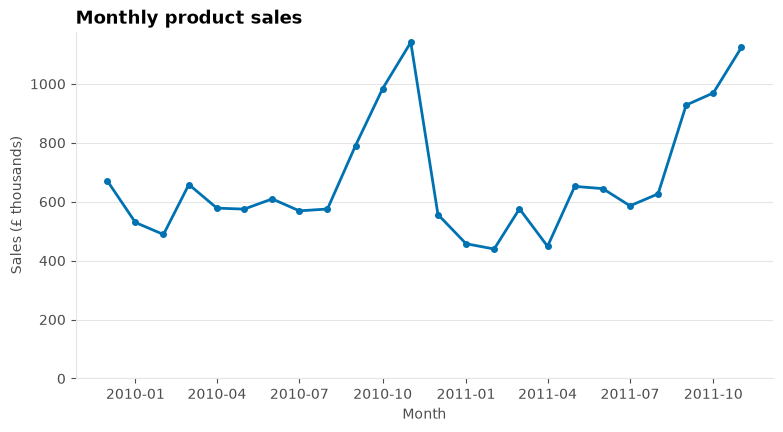

In [21]:
LAST_FULL_MONTH = datetime(2011, 11, 1)

monthly = (
    transactions.with_columns(month=pl.col("invoice_date").dt.truncate("1mo"))
    .filter(pl.col("month") <= LAST_FULL_MONTH)
    .group_by("month")
    .agg(revenue=pl.col("revenue").sum(), customers=pl.col("customer_id").n_unique())
    .sort("month")
)

fig, ax = plt.subplots()
ax.plot(monthly["month"], monthly["revenue"] / 1e3, marker="o", markersize=4, color=BLUE)
ax.set_title("Monthly product sales")
ax.set_xlabel("Month")
ax.set_ylabel("Sales (£ thousands)")
ax.set_ylim(bottom=0)
save_fig(fig, "01_monthly_revenue")
plt.show()

In [22]:
# The numbers behind the chart: sales per month (£ thousands)
with pl.Config(tbl_rows=30):
    print(monthly.select(month=pl.col("month").dt.strftime("%Y-%m"), sales_k=(pl.col("revenue") / 1e3).round(0)))

shape: (24, 2)
┌─────────┬─────────┐
│ month   ┆ sales_k │
│ ---     ┆ ---     │
│ str     ┆ f64     │
╞═════════╪═════════╡
│ 2009-12 ┆ 671.0   │
│ 2010-01 ┆ 530.0   │
│ 2010-02 ┆ 489.0   │
│ 2010-03 ┆ 658.0   │
│ 2010-04 ┆ 578.0   │
│ 2010-05 ┆ 575.0   │
│ 2010-06 ┆ 610.0   │
│ 2010-07 ┆ 569.0   │
│ 2010-08 ┆ 575.0   │
│ 2010-09 ┆ 791.0   │
│ 2010-10 ┆ 984.0   │
│ 2010-11 ┆ 1141.0  │
│ 2010-12 ┆ 557.0   │
│ 2011-01 ┆ 458.0   │
│ 2011-02 ┆ 439.0   │
│ 2011-03 ┆ 576.0   │
│ 2011-04 ┆ 449.0   │
│ 2011-05 ┆ 652.0   │
│ 2011-06 ┆ 644.0   │
│ 2011-07 ┆ 586.0   │
│ 2011-08 ┆ 627.0   │
│ 2011-09 ┆ 928.0   │
│ 2011-10 ┆ 969.0   │
│ 2011-11 ┆ 1124.0  │
└─────────┴─────────┘


### 4.2 Are active customers new or returning?

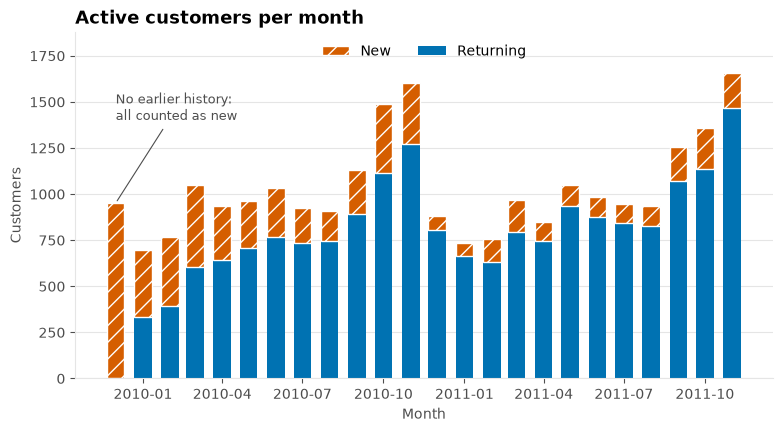

In [23]:
active = (
    transactions.with_columns(month=pl.col("invoice_date").dt.truncate("1mo"))
    .filter(pl.col("month") <= LAST_FULL_MONTH)
    .select("customer_id", "month")
    .unique()
    .join(first_purchase.with_columns(first_month=pl.col("first_purchase").dt.truncate("1mo")), on="customer_id")
    .group_by("month")
    .agg(
        new=(pl.col("month") == pl.col("first_month")).sum(),
        returning=(pl.col("month") > pl.col("first_month")).sum(),
    )
    .sort("month")
)

fig, ax = plt.subplots()
width = 20  # days
returning_bars = ax.bar(active["month"], active["returning"], width=width, color=BLUE, label="Returning")
new_bars = ax.bar(active["month"], active["new"], width=width, bottom=active["returning"], color=VERMILLION,
                  label="New", edgecolor="white", linewidth=1, hatch="//")
ax.set_ylim(top=ax.get_ylim()[1] * 1.08)
ax.annotate("No earlier history:\nall counted as new", (active["month"][0], active["new"][0]),
            xytext=(active["month"][0], active["new"][0] * 1.45), ha="left", va="bottom",
            color=INK_SECONDARY, fontsize=9,
            arrowprops={"arrowstyle": "-", "color": INK_SECONDARY, "linewidth": 0.8})
ax.set_title("Active customers per month")
ax.set_xlabel("Month")
ax.set_ylabel("Customers")
ax.legend(handles=[new_bars, returning_bars], loc="upper center", ncols=2)
save_fig(fig, "01_active_customers")
plt.show()

In [24]:
# Share of the active customers each month that are returning (earlier history exists from Jan 2010)
with pl.Config(tbl_rows=30):
    print(active.select(
        month=pl.col("month").dt.strftime("%Y-%m"),
        returning_pct=(pl.col("returning") / (pl.col("returning") + pl.col("new")) * 100).round(0),
    ))

shape: (24, 2)
┌─────────┬───────────────┐
│ month   ┆ returning_pct │
│ ---     ┆ ---           │
│ str     ┆ f64           │
╞═════════╪═══════════════╡
│ 2009-12 ┆ 0.0           │
│ 2010-01 ┆ 47.0          │
│ 2010-02 ┆ 51.0          │
│ 2010-03 ┆ 58.0          │
│ 2010-04 ┆ 69.0          │
│ 2010-05 ┆ 74.0          │
│ 2010-06 ┆ 74.0          │
│ 2010-07 ┆ 80.0          │
│ 2010-08 ┆ 82.0          │
│ 2010-09 ┆ 79.0          │
│ 2010-10 ┆ 75.0          │
│ 2010-11 ┆ 80.0          │
│ 2010-12 ┆ 91.0          │
│ 2011-01 ┆ 90.0          │
│ 2011-02 ┆ 83.0          │
│ 2011-03 ┆ 82.0          │
│ 2011-04 ┆ 88.0          │
│ 2011-05 ┆ 89.0          │
│ 2011-06 ┆ 89.0          │
│ 2011-07 ┆ 89.0          │
│ 2011-08 ┆ 88.0          │
│ 2011-09 ┆ 85.0          │
│ 2011-10 ┆ 84.0          │
│ 2011-11 ┆ 89.0          │
└─────────┴───────────────┘


In [25]:
new_2011 = active.filter(pl.col("month").dt.year() == 2011).select(
    month=pl.col("month").dt.strftime("%b"), new_customers=pl.col("new")
)
with pl.Config(tbl_cols=12):
    print(new_2011.transpose(column_names="month"))

shape: (1, 11)
┌─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┐
│ Jan ┆ Feb ┆ Mar ┆ Apr ┆ May ┆ Jun ┆ Jul ┆ Aug ┆ Sep ┆ Oct ┆ Nov │
│ --- ┆ --- ┆ --- ┆ --- ┆ --- ┆ --- ┆ --- ┆ --- ┆ --- ┆ --- ┆ --- │
│ u32 ┆ u32 ┆ u32 ┆ u32 ┆ u32 ┆ u32 ┆ u32 ┆ u32 ┆ u32 ┆ u32 ┆ u32 │
╞═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╡
│ 73  ┆ 126 ┆ 178 ┆ 106 ┆ 113 ┆ 108 ┆ 101 ┆ 108 ┆ 185 ┆ 221 ┆ 190 │
└─────┴─────┴─────┴─────┴─────┴─────┴─────┴─────┴─────┴─────┴─────┘


Customers active in December 2009 all count as *new*, because there is no earlier history. The first few months overstate acquisition, so the 2011 row is the fair view of when new customers arrive.

### 4.3 Where are customers based?

United Kingdom: 91.1% of customers


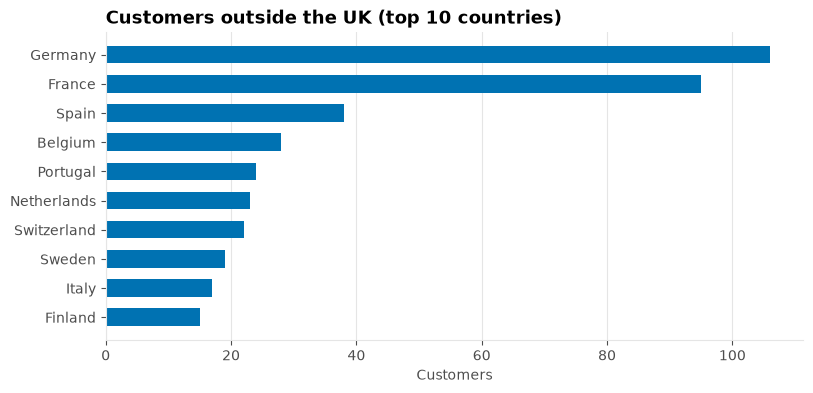

In [26]:
by_country = (
    customers.group_by("country").agg(customers=pl.len())
    .sort("customers", descending=True)
    .with_columns(pct=(pl.col("customers") / pl.col("customers").sum() * 100).round(1))
)
uk_share = by_country.filter(pl.col("country") == "United Kingdom")["pct"].item()
print(f"United Kingdom: {uk_share}% of customers")

top = by_country.filter(pl.col("country") != "United Kingdom").head(10).reverse()
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(top["country"], top["customers"], color=BLUE, height=0.6)
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_title("Customers outside the UK (top 10 countries)")
ax.set_xlabel("Customers")
save_fig(fig, "01_customers_by_country")
plt.show()

### 4.4 How often do customers buy?

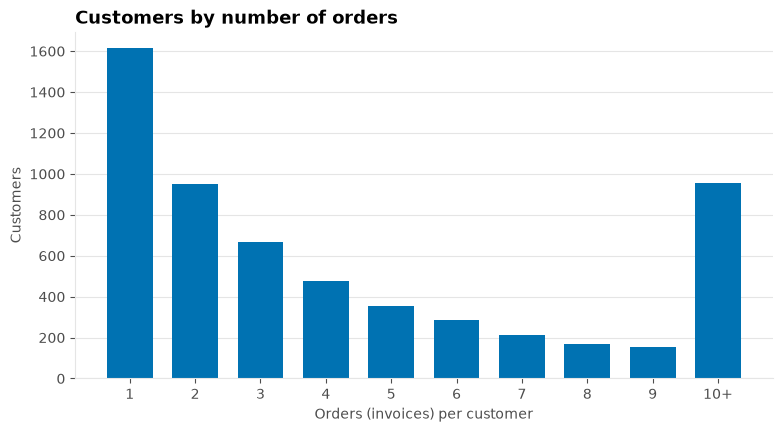

One-time buyers: 27.6%
Customers with 10+ orders: 957 (16.4%)
Median orders per customer: 3


In [27]:
orders = transactions.group_by("customer_id").agg(orders=pl.col("invoice").n_unique())
MAX_BUCKET = 10
order_counts = (
    orders.with_columns(bucket=pl.col("orders").clip(upper_bound=MAX_BUCKET))
    .group_by("bucket").len().sort("bucket")
)
labels = [str(b) if b < MAX_BUCKET else f"{MAX_BUCKET}+" for b in order_counts["bucket"]]

fig, ax = plt.subplots()
ax.bar(labels, order_counts["len"], color=BLUE, width=0.7)
ax.set_title("Customers by number of orders")
ax.set_xlabel("Orders (invoices) per customer")
ax.set_ylabel("Customers")
save_fig(fig, "01_orders_per_customer")
plt.show()

print(f"One-time buyers: {(orders['orders'] == 1).mean():.1%}")
print(f"Customers with {MAX_BUCKET}+ orders: {(orders['orders'] >= MAX_BUCKET).sum():,} ({(orders['orders'] >= MAX_BUCKET).mean():.1%})")
print(f"Median orders per customer: {orders['orders'].median():.0f}")

### 4.5 How much do customers spend?

In [28]:
spend = customers.filter(pl.col("included"))["net_revenue"].to_numpy()

pl.DataFrame({
    "statistic": ["mean", "median", "10% trimmed mean", "MAD", "max"],
    "net_revenue_gbp": [spend.mean(), np.median(spend), stats.trim_mean(spend, 0.1),
                        stats.median_abs_deviation(spend), spend.max()],
}).with_columns(pl.col("net_revenue_gbp").round(0))

statistic,net_revenue_gbp
str,f64
"""mean""",2789.0
"""median""",842.0
"""10% trimmed mean""",1274.0
"""MAD""",621.0
"""max""",570381.0


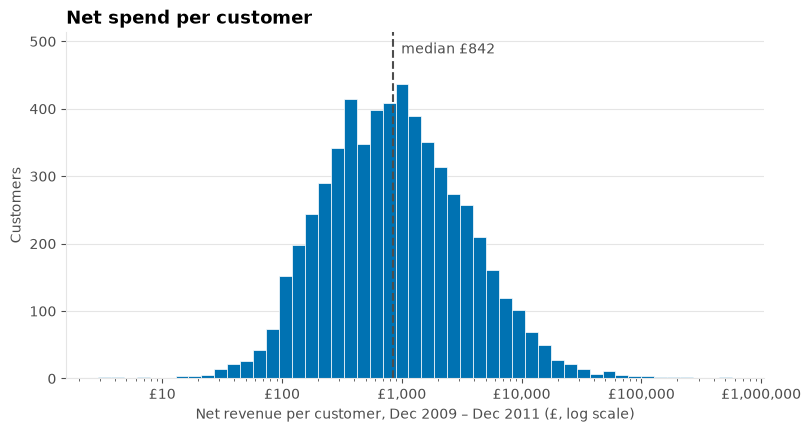

In [29]:
fig, ax = plt.subplots()
bins = np.logspace(np.log10(spend.min()), np.log10(spend.max()), 50)
ax.hist(spend, bins=bins, color=BLUE, edgecolor="white", linewidth=0.5)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"£{x:,.0f}"))
median_spend = np.median(spend)
ax.set_ylim(top=ax.get_ylim()[1] * 1.12)
ax.axvline(median_spend, color=INK_SECONDARY, linestyle="--", linewidth=1.5)
ax.annotate(f"median £{median_spend:,.0f}", (median_spend, ax.get_ylim()[1] * 0.97), xytext=(6, 0),
            textcoords="offset points", color=INK_SECONDARY, va="top")
ax.set_title("Net spend per customer")
ax.set_xlabel("Net revenue per customer, Dec 2009 – Dec 2011 (£, log scale)")
ax.set_ylabel("Customers")
save_fig(fig, "01_spend_per_customer")
plt.show()

### 4.6 How concentrated is revenue?

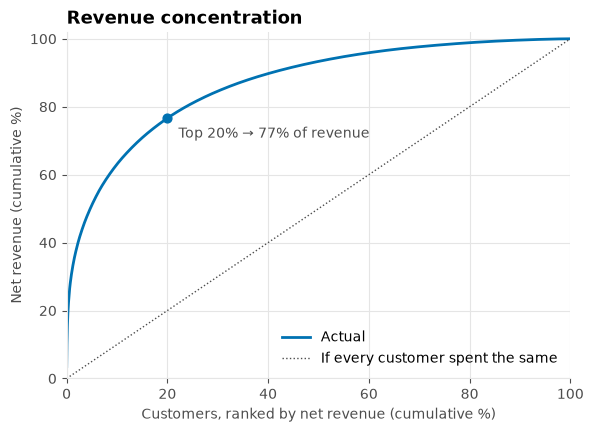

Top 20% of customers: 77% of net revenue


In [30]:
sorted_spend = np.sort(spend)[::-1]
customer_share = np.arange(1, len(sorted_spend) + 1) / len(sorted_spend)
revenue_share = np.cumsum(sorted_spend) / sorted_spend.sum()
top20_share = revenue_share[int(0.2 * len(sorted_spend)) - 1]

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(customer_share * 100, revenue_share * 100, color=BLUE, label="Actual")
ax.plot([0, 100], [0, 100], color=INK_SECONDARY, linestyle=":", linewidth=1, label="If every customer spent the same")
ax.scatter([20], [top20_share * 100], color=BLUE, s=40, zorder=3)
ax.annotate(f"Top 20% → {top20_share:.0%} of revenue", (20, top20_share * 100), xytext=(8, -14),
            textcoords="offset points", color=INK_SECONDARY)
ax.set_title("Revenue concentration")
ax.set_xlabel("Customers, ranked by net revenue (cumulative %)")
ax.set_ylabel("Net revenue (cumulative %)")
ax.set_xlim(0, 100)
ax.set_ylim(0, 102)
ax.grid(axis="x")
ax.legend(loc="lower right")
save_fig(fig, "01_revenue_concentration")
plt.show()
print(f"Top 20% of customers: {top20_share:.0%} of net revenue")

### 4.7 How long between purchases?

This sets the scale for *recency* in `02` and informs the churn window in `04`. Gaps are measured between distinct purchase days, so several invoices on the same day count once. There are two ways to summarise them:

- **All gaps pooled**: frequent buyers contribute many gaps, so they dominate.
- **Median gap per customer**: each customer counts once.

In [31]:
purchase_days = transactions.select("customer_id", day=pl.col("invoice_date").dt.date()).unique()
gaps = (
    purchase_days.sort("customer_id", "day")
    .with_columns(gap_days=pl.col("day").diff().over("customer_id").dt.total_days())
    .drop_nulls("gap_days")
)
typical_gap = gaps.group_by("customer_id").agg(median_gap=pl.col("gap_days").median())["median_gap"]

print(f"Customers with 2+ purchase days: {typical_gap.len():,} of {transactions['customer_id'].n_unique():,}")
QUANTILES = (0.5, 0.75, 0.9)
pl.DataFrame({
    "quantile": [f"{q:.0%}" for q in QUANTILES],
    "all_gaps_pooled_days": [gaps["gap_days"].quantile(q) for q in QUANTILES],
    "median_gap_per_customer_days": [typical_gap.quantile(q) for q in QUANTILES],
})

Customers with 2+ purchase days: 4,172 of 5,839


quantile,all_gaps_pooled_days,median_gap_per_customer_days
str,f64,f64
"""50%""",32.0,65.0
"""75%""",71.0,131.5
"""90%""",148.0,245.0


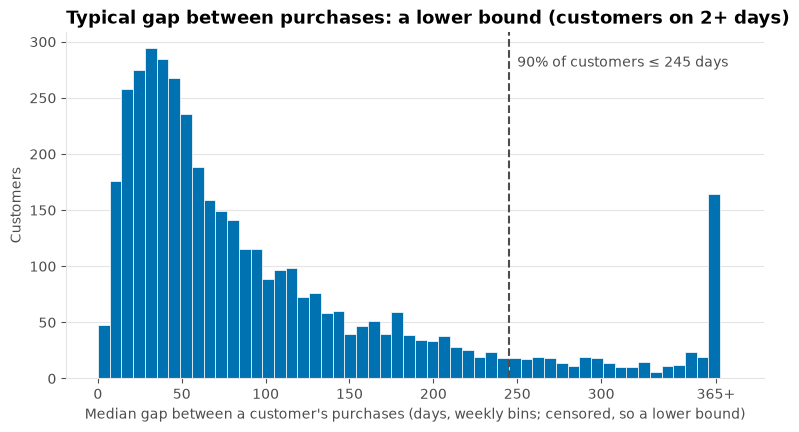

In [32]:
MAX_DAYS = 365
BIN_WIDTH = 7
fig, ax = plt.subplots()
ax.hist(typical_gap.clip(upper_bound=MAX_DAYS), bins=np.arange(0, MAX_DAYS + 2 * BIN_WIDTH, BIN_WIDTH),
        color=BLUE, edgecolor="white", linewidth=0.5)
p90 = typical_gap.quantile(0.9)
ax.axvline(p90, color=INK_SECONDARY, linestyle="--", linewidth=1.5)
ax.annotate(f"90% of customers ≤ {p90:.0f} days", (p90, ax.get_ylim()[1] * 0.9), xytext=(6, 0),
            textcoords="offset points", color=INK_SECONDARY)
ticks = list(range(0, 301, 50)) + [MAX_DAYS + BIN_WIDTH / 2]
ax.set_xticks(ticks, [str(t) for t in ticks[:-1]] + [f"{MAX_DAYS}+"])
ax.set_title("Typical gap between purchases: a lower bound (customers on 2+ days)")
ax.set_xlabel("Median gap between a customer's purchases (days, weekly bins; censored, so a lower bound)")
ax.set_ylabel("Customers")
save_fig(fig, "01_days_between_purchases")
plt.show()

**Both views underestimate long gaps.** A gap is only observed if the customer came back before December 2011. The final, open-ended gap of a customer who left is never seen, and the data covers only two years. These quantiles are a lower bound on how long customers stay quiet, so they cannot fix the churn window on their own. `04` will set it with a method that accounts for this censoring.

### 4.8 How common are cancellations?

In [33]:
cancelled_share = (
    lines.filter(pl.col("kind") == "sale").group_by("customer_id").agg(sales=pl.col("revenue").sum())
    .join(lines.filter(pl.col("kind") == "cancellation").group_by("customer_id")
          .agg(cancelled=-pl.col("revenue").sum()), on="customer_id", how="left")
    .with_columns(pl.col("cancelled").fill_null(0))
    .with_columns(share=pl.col("cancelled") / pl.col("sales"))
)
cancellers = cancelled_share.filter(pl.col("cancelled") > 0)
print(f"Customers with at least one product cancellation: {cancellers.height / cancelled_share.height:.1%}")
print(f"Median cancelled share of their product sales: {cancellers['share'].median():.1%}")

Customers with at least one product cancellation: 41.4%
Median cancelled share of their product sales: 2.0%


**Findings: customer behaviour**

- **Strong seasonality.** Sales climb from September and peak in November, ahead of Christmas (giftware). A quiet spring is normal, so the churn definition in `04` must not mistake it for churn.
- **The business runs on returning customers.** From mid-2010 they make up most of each month's active base. In 2011, new customers peak in September–November. The early months of 2010 overstate acquisition, because there is no earlier history.
- **The UK is 91% of customers**, so country is too unbalanced to drive segmentation.
- **Frequency is very uneven.** More than a quarter of customers bought only once, while about one in six placed 10 or more orders.
- **Net spend is strongly right-skewed** (mean ≈ 3× median), and so is the number of orders. Both need a log transform before K-Means. Recency's distribution is checked in `02`.
- **Revenue is concentrated.** The top 20% of customers bring in about three quarters of net revenue.
- **The typical repeat customer buys about every two months.** Pooled gaps look shorter (about a month) because frequent buyers dominate them. Both views underestimate long silences, so the churn window is left open for `04`.
- **Cancellations are common but small.** 4 in 10 customers cancel something, typically a small share of their purchases.

## Summary

**Outputs** (`data/processed/`):
- `lines.parquet`: all clean lines (sale, cancellation, correction) before matching. This is the input of `split_purchases()`.
- `transactions.parquet`: product sale lines, with cancelled sales removed in matched pairs.
- `adjustments.parquet`: unmatched cancellations and manual corrections (`kind` column), with negative or positive revenue.
- `customers.parquet`: sales, adjustments, net revenue, main country and the `included` flag for each customer.

**Cleaning decisions:**
- Drop the sheet overlap, exact duplicates, lines without a customer, non-goods charges and invalid lines.
- Remove cancelled product sales in matched pairs. Keep everything else that changes what a customer paid (unmatched cancellations, manual corrections, discounts) as adjustments, which count only in net revenue.
- `transactions` uses cancellations from the whole period, which is right for `02` and `03` (one snapshot at the end).

**Implications for the next notebooks:**
- `02` RFM + K-Means: recency and frequency come from `transactions`, and monetary is `net_revenue`. Use only `included` customers, log-transform the skewed variables, and leave country out.
- `03` cohorts: the first cohort (Dec 2009) contains earlier customers too, and December 2011 is a partial month.
- `04` churn: rebuild purchases with `split_purchases(lines, as_of=cutoff)`, so that later cancellations do not leak into the features. The window is not settled yet: the observed gaps are censored and depend on seasonality.